In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import trange, tqdm
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoImageProcessor
from itertools import islice
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# load model
_DINO_ID = "facebook/dinov2-base"
dino_model = AutoModel.from_pretrained(_DINO_ID).to(device).eval()
dino_processor = AutoImageProcessor.from_pretrained(_DINO_ID)

/home/kpetrakis/trunk-filtering/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 8748.92it/s]


In [3]:
# Data load
'''
inference/trunk_export/
  crops/{key}.png        one per trunk detection, WITH context margin (lossless)
  meta.csv               key, stem, frame, x1..y2, crop offset, conf, depth_q25, box_h
  references.json        the annotator's fg/bg picks as keys (written at filter time)
inference/trunk_embeddings.npz   (already exists) current SigLIP embeddings
'''

DATA_ROOT = Path("../data/ab9cadb8-a4be-4357-b2d6-b781b625a2f9")
INFERENCE_ROOT = DATA_ROOT / "inference"
CROPS_ROOT = INFERENCE_ROOT / "trunk_export/crops"
meta_path = INFERENCE_ROOT / "trunk_export" / "meta.csv"

meta = pd.read_csv(meta_path)
npz = np.load(INFERENCE_ROOT / "trunk_embeddings.npz", allow_pickle=True)
siglip = dict(zip(npz["keys"].astype(str), npz["emb"]))                                  # key -> (1152,)
# print("Available arrays:", npz.files)
# for name in npz.files:
#   arr = npz[name]
#   print(f"\narray {name}:")
#   print("  Shape:", arr.shape)
#   print("  Dtype:", arr.dtype)
#   print("  Values:\n", arr[:5] if arr.ndim > 0 else arr)

refs = json.loads((INFERENCE_ROOT / "trunk_export/references.json").read_text())
meta["ref"] = meta["key"].map({**{k: "fg" for k in refs["fg"]}, **{k: "bg" for k in refs["bg"]}})  # fg / bg / NaN

In [ ]:
def letterbox(image: Image.Image,
    size=(224, 224),  # (width, height)
    fill=(127, 127, 127)) -> Image.Image:

	image = image.convert("RGB")
	target_w, target_h = size
	w, h = image.size

	# Scale to fit without distorting the aspect ratio
	scale = min(target_w / w, target_h / h)

	new_w = max(1, round(w * scale))
	new_h = max(1, round(h * scale))

	resized = image.resize((new_w, new_h), Image.Resampling.LANCZOS)

	# Center the resized crop on the canvas
	canvas = Image.new("RGB", (target_w, target_h), fill)

	left = (target_w - new_w) // 2
	top = (target_h - new_h) // 2

	canvas.paste(resized, (left, top))
	return canvas

def show_processed_image(pixel_values, mean, std):
    x = pixel_values.detach().cpu()[0].permute(1, 2, 0).numpy()

    mean = np.asarray(mean, dtype=np.float32)
    std = np.asarray(std, dtype=np.float32)

    x = x * std + mean
    x = np.clip(x, 0, 1)

    plt.imshow(x)
    plt.axis("off")
    plt.show()


def mean_padding_color(image_mean):
    return tuple(round(255 * min(1.0, max(0.0, m))) for m in image_mean)

dino_mean = proc_kw["image_mean"]
dino_pad_color = mean_padding_color(dino_mean)

# kai meta kane:
# crop_letterbox_mean = letterbox(
#     crop,
#     size=(224, 224),
#     fill=dino_pad_color,
# )
print(dino_pad_color)

KeyError: 'image_mean'

key = L_1782121838_p0000_chunk_005_000001_162_1105


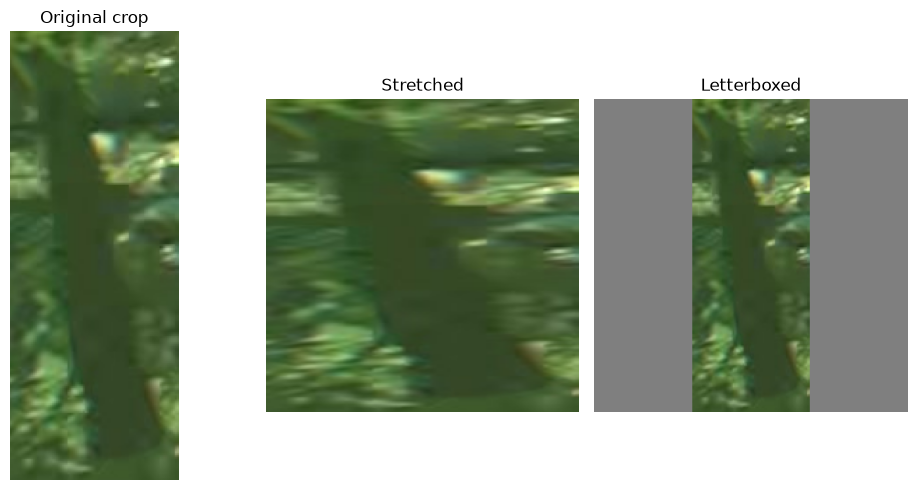

key = L_1782121838_p0000_chunk_005_000001_1021_1036


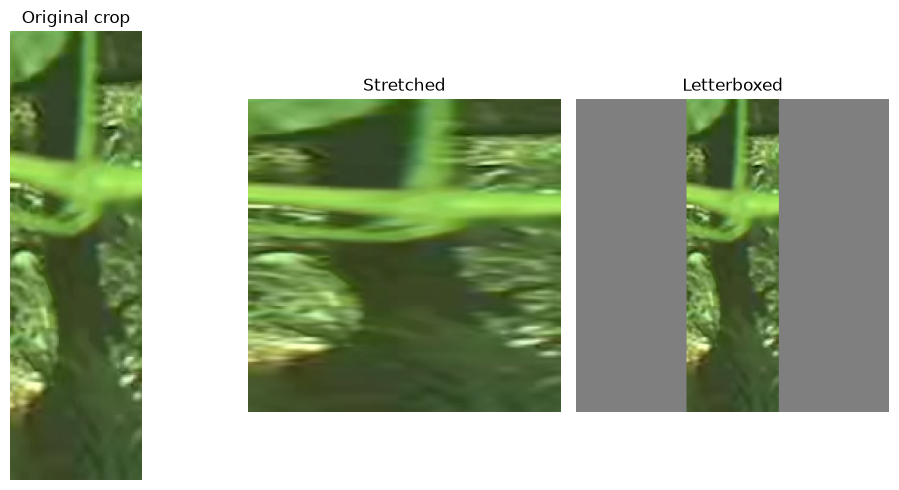

In [ ]:
# proc_kw = {'do_center_crop':False, 'size':{"height": 224, "width": 224}}
# proc_kw = dict()
proc_kw = {
  'size':{"height": 224, "width": 224},
  'do_center_crop':False,
  "do_rescale": True,
  "do_normalize": True,
  # "image_mean": [0.30873852713668126, 0.40787950169456705, 0.2226692956750353],
  # "image_std":  [0.11958446534026305, 0.13250266414996473, 0.10012729012265584]
}

# Start with neutral gray padding.
PAD_COLOR = (127, 127, 127)

for _, row in islice(meta.iterrows(), 2):
    print(f"key = {row.key}")

    img_path = CROPS_ROOT / f"{row.key}.png"
    img = Image.open(img_path).convert("RGB")

    # Detection coordinates inside the source crop
    bx1, by1 = row.x1 - row.crop_x1, row.y1 - row.crop_y1                     # box inside the crop
    bx2, by2 = row.x2 - row.crop_x1, row.y2 - row.crop_y1

    crop = img.crop((bx1, by1, bx2, by2))

    # Variant 1: your existing direct-resize baseline
    proc_stretch = dino_processor(
        images=crop,
        return_tensors="pt",
        **proc_kw,
    ).to(device)
    # Variant 2: preserve aspect ratio using letterboxing
    crop_letterbox = letterbox(crop, size=(224, 224), fill=PAD_COLOR)

    proc_letterbox = dino_processor(
        images=crop_letterbox,
        return_tensors="pt",
        **proc_kw,
    ).to(device)

    # Visualize the PIL images before normalization
    fig, axes = plt.subplots(1, 3, figsize=(10, 5))
    axes[0].imshow(crop)
    axes[0].set_title("Original crop")

    axes[1].imshow(crop.resize((224, 224)))
    axes[1].set_title("Stretched")

    axes[2].imshow(crop_letterbox)
    axes[2].set_title("Letterboxed")
    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# 1. Mixel Input!

# proc_kw = {'do_center_crop':False, 'size':{"height": 224, "width": 224}}
# proc_kw = dict()
proc_kw = {
  'size':{"height": 224, "width": 224},
  'do_center_crop':False,
  "do_rescale": True,
  "do_normalize": True,
  # "image_mean": [0.30873852713668126, 0.40787950169456705, 0.2226692956750353],
  # "image_std":  [0.11958446534026305, 0.13250266414996473, 0.10012729012265584]
}

for _, row in islice(meta.iterrows(), 2):
  print(f"key = {row.key}")
  img_path = CROPS_ROOT / f"{row.key}.png"
  img = Image.open(img_path).convert("RGB")
  bx1, by1 = row.x1 - row.crop_x1, row.y1 - row.crop_y1                     # box inside the crop
  bx2, by2 = row.x2 - row.crop_x1, row.y2 - row.crop_y1
  crop = img.crop((bx1, by1, bx2, by2))
  proc_img = dino_processor(images=img, return_tensors="pt", **proc_kw).to(device)
  proc_crop = dino_processor(images=img, return_tensors="pt", **proc_kw).to(device)
  # proc_img = processor(images=img, return_tensors="pt", **proc_kw).to(device) # siglip pre-processing
  # proc_crop = processor(images=crop, return_tensors="pt", **proc_kw).to(device) # siglip pre-processing
  # print(proc_img)